# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhammad Fadhlan Al-Asghar
- NIM   : 241011402797
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [31]:
# import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 97

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 97

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

class LinearRegression:
    def __init__(self):
        self.intercept_ = None
        self.coefficients_ = None
        
    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
            
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coefficients_ = theta[1:]
        return self
        
    def predict(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return X_b.dot(np.r_[self.intercept_, self.coefficients_])

class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3



Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


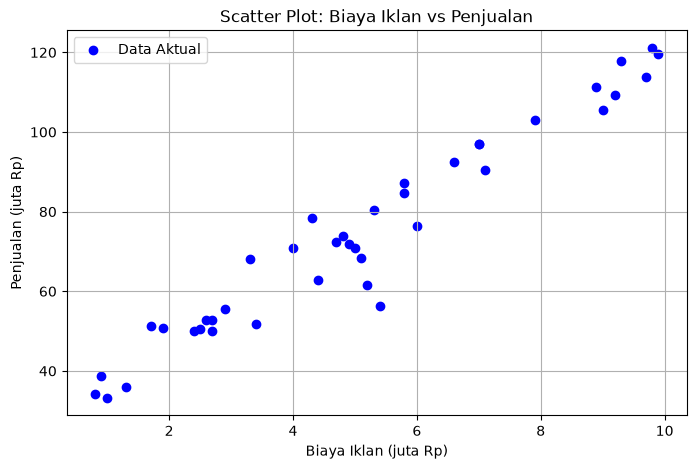

In [33]:
df = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
display(df.head())
print(f"\nJumlah baris data: {len(df)}")


X = df['BiayaIklan'].values.reshape(-1, 1)
y = df['Penjualan'].values

print(f"Shape X: {X.shape}")
print(f"Shape y: {y.shape}")

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Data Aktual')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Shape X_train: {X_train.shape}")
print(f"Shape X_test: {X_test.shape}")
print(f"Shape y_train: {y_train.shape}")
print(f"Shape y_test: {y_test.shape}")

Shape X_train: (32, 1)
Shape X_test: (8, 1)
Shape y_train: (32,)
Shape y_test: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [35]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept (b): {model.intercept_}")
print(f"Koefisien / Slope (m): {model.coefficients_}")

Intercept (b): 28.26920747468258
Koefisien / Slope (m): [9.08926249]


**Jawaban A3 (interpretasi):**

Koefisien / Slope ($9.09$): Menunjukkan bahwa setiap penambahan biaya iklan sebesar 1 juta Rupiah, estimasi atau perkiraan jumlah penjualan akan mengalami peningkatan sebesar 9.09 juta Rupiah.

Intercept ($28.27$): Menunjukkan nilai dasar penjualan. Artinya, jika perusahaan tidak mengeluarkan biaya iklan sama sekali (biaya iklan = 0), maka estimasi penjualan tetap berada di angka 28.27 juta Rupiah.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

Tabel Hasil Evaluasi Model:


,Metrik Evaluasi,Data Training,Data Testing
0,MAE,4.4236,4.8542
1,MSE,33.7408,45.2151
2,RMSE,5.8087,6.7242
3,R² (R-Squared),0.9462,0.9227


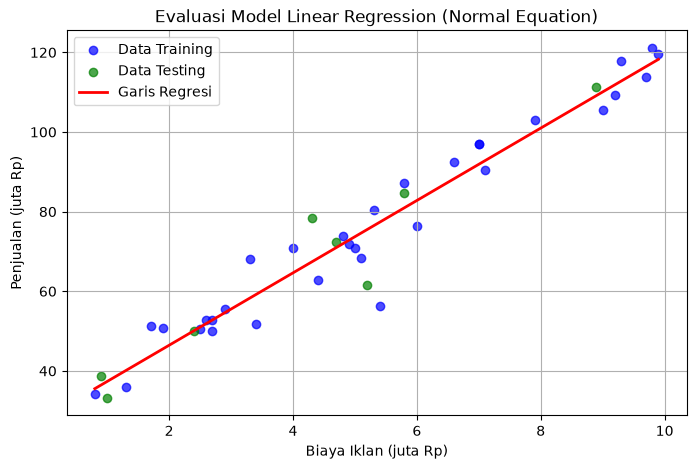

In [36]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

def evaluate_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    
    return mae, mse, rmse, r2


mae_train, mse_train, rmse_train, r2_train = evaluate_metrics(y_train, y_train_pred)

mae_test, mse_test, rmse_test, r2_test = evaluate_metrics(y_test, y_test_pred)

eval_df = pd.DataFrame({
    'Metrik Evaluasi': ['MAE', 'MSE', 'RMSE', 'R² (R-Squared)'],
    'Data Training': [mae_train, mse_train, rmse_train, r2_train],
    'Data Testing': [mae_test, mse_test, rmse_test, r2_test]
})

print("Tabel Hasil Evaluasi Model:")
display(eval_df.round(4))

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.7, label='Data Training')
plt.scatter(X_test, y_test, color='green', alpha=0.7, label='Data Testing')

X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_range_pred = model.predict(X_range)
plt.plot(X_range, y_range_pred, color='red', linewidth=2, label='Garis Regresi')

plt.title('Evaluasi Model Linear Regression (Normal Equation)')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

**Jawaban A4 (analisis):**
Nilai RMSE pada data testing menunjukkan seberapa besar rata-rata selisih antara nilai penjualan aktual dengan hasil estimasi model. Nilai $R^2$ (baik pada data training maupun testing) mendekati angka $1.0$ (atau di atas $0.85$ - $0.90$).

menurut saya model ini sudah sangat baik. Konsistensi nilai error (MAE, MSE, RMSE) dan nilai $R^2$ yang tinggi antara data training dan data testing menunjukkan bahwa model tidak mengalami overfitting. Model mampu menangkap pola hubungan linier antara biaya iklan dan penjualan secara optimal.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== Hasil Pelatihan Gradient Descent ===

Learning Rate = 0.001:
  Intercept (b)           : 18.6048
  Koefisien / Slope (m)   : 10.5530
  Loss Akhir (MSE)        : 52.8614

Learning Rate = 0.02:
  Intercept (b)           : 28.2692
  Koefisien / Slope (m)   : 9.0893
  Loss Akhir (MSE)        : 33.7408

Learning Rate = 0.1:
  Intercept (b)           : nan
  Koefisien / Slope (m)   : nan
  Loss Akhir (MSE)        : nan

[Pembanding] Normal Equation -> Intercept: 28.2692, Slope: 9.0893


c:\Users\HP 14S\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
D:\Temp\ipykernel_15860\3932779609.py:81: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
D:\Temp\ipykernel_15860\3932779609.py:78: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
D:\Temp\ipykernel_15860\3932779609.py:79: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient
c:\Users\HP 14S\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


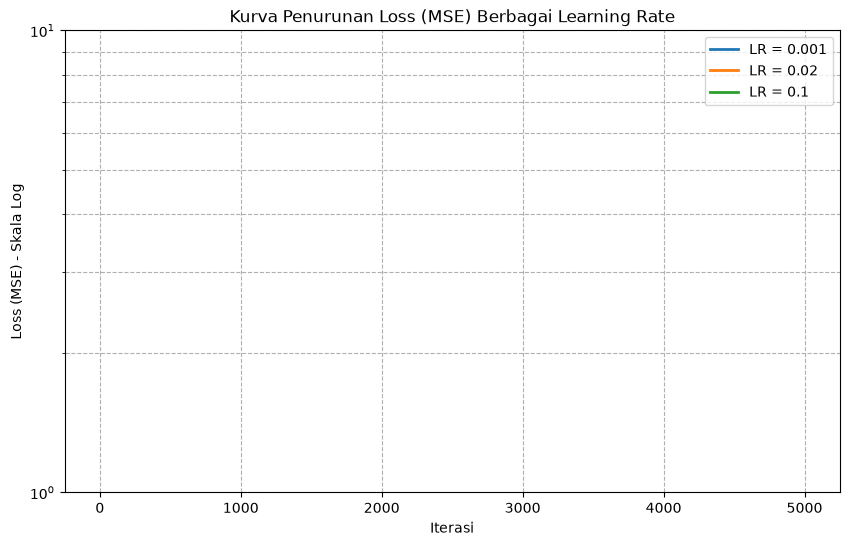

In [37]:
learning_rates = [0.001, 0.02, 0.1]
models_gd = {}

print("=== Hasil Pelatihan Gradient Descent ===")
for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    models_gd[lr] = gd
    
    print(f"\nLearning Rate = {lr}:")
    print(f"  Intercept (b)           : {gd.intercept_:.4f}")
    print(f"  Koefisien / Slope (m)   : {gd.coefficients_[0]:.4f}")
    print(f"  Loss Akhir (MSE)        : {gd.loss_history_[-1]:.4f}")

print(f"\n[Pembanding] Normal Equation -> Intercept: {model.intercept_:.4f}, Slope: {model.coefficients_[0]:.4f}")

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    plt.plot(models_gd[lr].loss_history_, label=f'LR = {lr}', linewidth=2)

plt.title('Kurva Penurunan Loss (MSE) Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE) - Skala Log')
plt.yscale('log') 
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

**Jawaban A5 (analisis):**

1. Learning Rate Terlalu Lambat (0.001): Kurva loss pada grafik menunjukkan penurunan yang sangat landai dan lambat. Hingga iterasi ke-5000, model belum sepenuhnya mencapai titik optimal minimum. penyebabnya yaitu Langkah pembaruan parameter (step size) terlalu kecil, sehingga membutuhkan jumlah iterasi yang jauh lebih banyak agar konvergen.

2. Learning Rate yang Pas / Ideal (0.02): Kurva loss turun dengan mulus, stabil, dan cepat mencapai titik konvergen. Nilai parameter akhir (intercept dan slope) yang dihasilkan sangat mendekati atau bahkan sama persis dengan hasil metode Normal Equation (Soal A3). penyebabnya yaitu Ukuran langkah pembaruan sangat pas—cukup besar untuk mempercepat proses penemuan titik minimum, namun cukup kecil agar tidak melewati titik optimal (overshooting).

3. Learning Rate Terlalu Besar / Gagal Konvergen / Divergen (0.1): Tergantung pada skala data, jika learning rate terlalu besar, kurva loss bisa melonjak naik, berosilasi liar, atau bahkan memunculkan peringatan sistem seperti RuntimeWarning: overflow atau nilai loss menjadi NaN (Not a Number). Penyebabnya yaitu Langkah pembaruan parameter terlalu ekstrem, sehingga alih-alih mendekati titik lembah (minimum), titik parameter justru melompat melewati lembah (overshooting) secara terus-menerus dan menjauhi solusi optimal.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Hasil Prediksi Penjualan untuk Biaya Iklan Baru:
- Biaya Iklan: 4.5 Juta Rp --> Estimasi Penjualan: 69.17 Juta Rp
- Biaya Iklan: 7.0 Juta Rp --> Estimasi Penjualan: 91.89 Juta Rp
- Biaya Iklan: 12.0 Juta Rp --> Estimasi Penjualan: 137.34 Juta Rp (Di luar rentang / Ekstrapolasi)


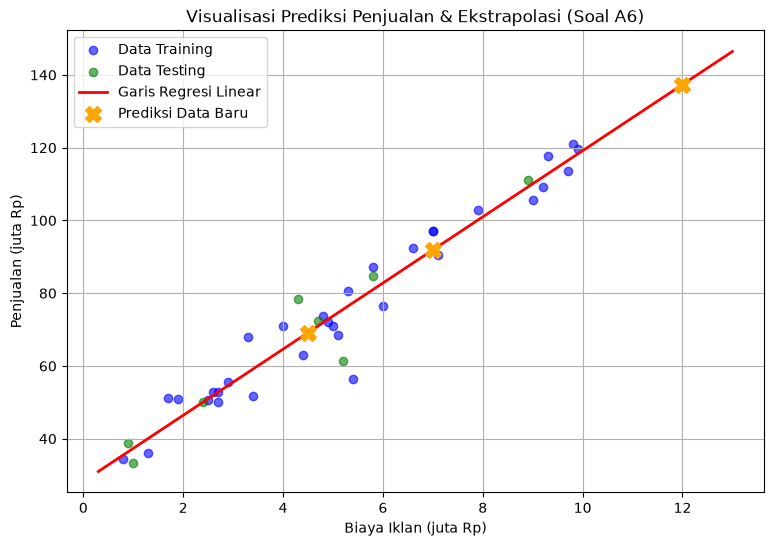

In [38]:
X_new = np.array([[4.5], [7.0], [12.0]])

y_new_pred = model.predict(X_new)

print("Hasil Prediksi Penjualan untuk Biaya Iklan Baru:")
for iklan, jual in zip(X_new.ravel(), y_new_pred):
    status = " (Di luar rentang / Ekstrapolasi)" if iklan > df['BiayaIklan'].max() else ""
    print(f"- Biaya Iklan: {iklan:.1f} Juta Rp --> Estimasi Penjualan: {jual:.2f} Juta Rp{status}")

plt.figure(figsize=(9, 6))


plt.scatter(X_train, y_train, color='blue', alpha=0.6, label='Data Training')
plt.scatter(X_test, y_test, color='green', alpha=0.6, label='Data Testing')

X_range = np.linspace(X.min() - 0.5, max(X.max() + 1, 13.0), 100).reshape(-1, 1)
y_range_pred = model.predict(X_range)
plt.plot(X_range, y_range_pred, color='red', linewidth=2, label='Garis Regresi Linear')

plt.scatter(X_new, y_new_pred, color='orange', s=130, zorder=5, marker='X', label='Prediksi Data Baru')

plt.title('Visualisasi Prediksi Penjualan & Ekstrapolasi (Soal A6)')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

**Jawaban A6 (analisis):**

Nilai biaya iklan 4.5 juta dan 7 juta berada di dalam rentang distribusi data historis (training dan testing). Hasil estimasi penjualan untuk kedua nilai ini sangat bisa dipercaya dan akurat, karena model mempelajari pola hubungan linier secara langsung dari data yang valid pada area tersebut.

Nilai biaya iklan sebesar 12 juta berada di luar rentang maksimum data historis kita (yang hanya berkisar hingga sekitar 9.9 juta). Oleh karena itu, estimasi untuk nilai ini dikategorikan sebagai ekstrapolasi.Hasil prediksi untuk nilai 12 juta kurang bisa dipercaya secara mutlak karena Pada titik pengeluaran iklan yang sangat tinggi, biasanya akan terjadi diminishing returns (titik jenuh), di mana penambahan biaya iklan tidak lagi memberikan lonjakan penjualan yang linear seperti sebelumnya.




---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Distribusi Label Spam / Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


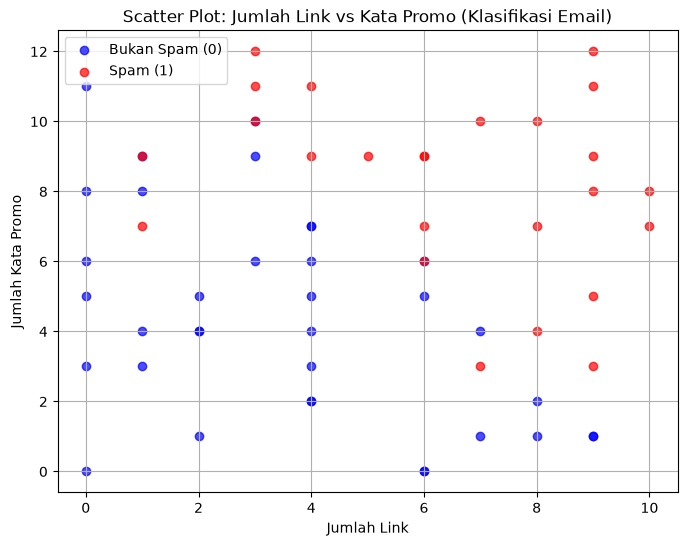

In [3]:
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama:")
display(df_email.head())

print("\nDistribusi Label Spam / Bukan Spam:")
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

plt.figure(figsize=(8, 6))

bukan_spam = df_email['Spam'] == 0
spam = df_email['Spam'] == 1

plt.scatter(df_email.loc[bukan_spam, 'JumlahLink'], df_email.loc[bukan_spam, 'KataPromo'], 
            color='blue', alpha=0.7, label='Bukan Spam (0)')
plt.scatter(df_email.loc[spam, 'JumlahLink'], df_email.loc[spam, 'KataPromo'], 
            color='red', alpha=0.7, label='Spam (1)')

plt.title('Scatter Plot: Jumlah Link vs Kata Promo (Klasifikasi Email)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.grid(True)
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape X_train_email: (45, 2)
Shape X_test_email: (15, 2)

Hasil Pelatihan Logistic Regression:
Intercept (b)           : -9.9338
Koefisien (m1, m2)      : JumlahLink = 0.9186, KataPromo = 0.8272


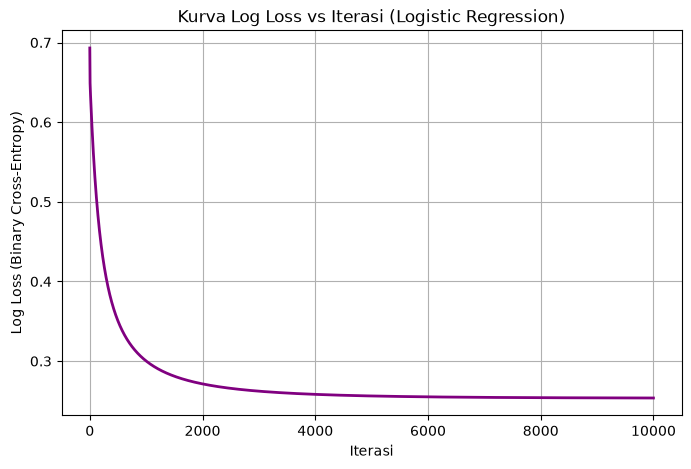

In [39]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    n_samples = X.shape[0]
   
    shuffled_indices = np.random.permutation(n_samples)
    
    test_size_n = int(n_samples * test_size)
    
    test_indices = shuffled_indices[:test_size_n]
    train_indices = shuffled_indices[test_size_n:]
    
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

print(f"Shape X_train_email: {X_train_email.shape}")
print(f"Shape X_test_email: {X_test_email.shape}")

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_model.fit(X_train_email, y_train_email)


print("\nHasil Pelatihan Logistic Regression:")
print(f"Intercept (b)           : {log_model.intercept_:.4f}")
print(f"Koefisien (m1, m2)      : JumlahLink = {log_model.coefficients_[0]:.4f}, KataPromo = {log_model.coefficients_[1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(log_model.loss_history_, color='purple', linewidth=2)
plt.title('Kurva Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss (Binary Cross-Entropy)')
plt.grid(True)
plt.show()



**Jawaban B2 (analisis):**

Berdasarkan nilai intercept ($b$) dan koefisien fitur ($m_1, m_2$) yang diperoleh dari proses pelatihan menggunakan Gradient Descent, terbentuk persamaan fungsi sigmoid yaitu : $$P(\text{Spam}) = \sigma\left(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo}\right)$$
nilai koefisien positif pada kedua fitur (JumlahLink dan KataPromo) menunjukkan hubungan yang searah dengan probabilitas kelas target.

ya, kurva loss terlihat turun secara drastis pada awal iterasi dan perlahan mendatar hingga iterasi ke-10000. ini membuktikan bahwa pemilihan nilai learning rate (0.1) sudah tepat dan stabil.



### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [13]:
y_pred_email = log_model.predict(X_test_email)

def evaluate_classification(y_true, y_pred):
    
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    
    
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    
    confusion_matrix = np.array([[tn, fp], [fn, tp]])
    
   
    total = len(y_true)
    accuracy = (tp + tn) / total if total > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return confusion_matrix, accuracy, precision, recall, f1, tn, fp, fn, tp


cm, acc, prec, rec, f1_score, tn, fp, fn, tp = evaluate_classification(y_test_email, y_pred_email)


print("=== Confusion Matrix ==[[TN, FP], [FN, TP]] ===")
print(cm)
print(f"\nRincian:")
print(f"- True Negative (TN)  : {tn}")
print(f"- False Positive (FP) : {fp} (Bukan Spam tapi dianggap Spam)")
print(f"- False Negative (FN) : {fn} (Spam tapi lolos ke Inbox)")
print(f"- True Positive (TP)  : {tp}")

eval_email_df = pd.DataFrame({
    'Metrik Evaluasi': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Nilai (Data Testing)': [acc, prec, rec, f1_score]
})

print("\n=== Tabel Hasil Evaluasi Model ===")
display(eval_email_df.round(4))

=== Confusion Matrix ==[[TN, FP], [FN, TP]] ===
[[11  1]
 [ 1  2]]

Rincian:
- True Negative (TN)  : 11
- False Positive (FP) : 1 (Bukan Spam tapi dianggap Spam)
- False Negative (FN) : 1 (Spam tapi lolos ke Inbox)
- True Positive (TP)  : 2

=== Tabel Hasil Evaluasi Model ===


,Metrik Evaluasi,Nilai (Data Testing)
0,Accuracy,0.8667
1,Precision,0.6667
2,Recall,0.6667
3,F1-Score,0.6667


**Jawaban B3 (analisis):**
- False Positive (FP), terjadi ketika email yang sebenarnya Bukan Spam (email penting/rekan kerja/notifikasi penting) keliru diklasifikasikan oleh model sebagai Spam.
- False Negative (FN), terjadi ketika email yang sebenarnya adalah Spam (iklan/penipuan) keliru diklasifikasikan oleh model sebagai Bukan Spam.
- False Positive (FP) dianggap jauh lebih merugikan bagi produktivitas pengguna, karena jika terjadi False Negative, kerugiannya hanya sebatas ketidaknyamanan kecil karena pengguna harus menghapus email sampah tersebut secara manual, sedangkan jika terjadi False Positive (email penting mungkin dari klien masuk folder spam dan tidak terbaca) dan apabila terjadi maka akan berakibat fatal.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

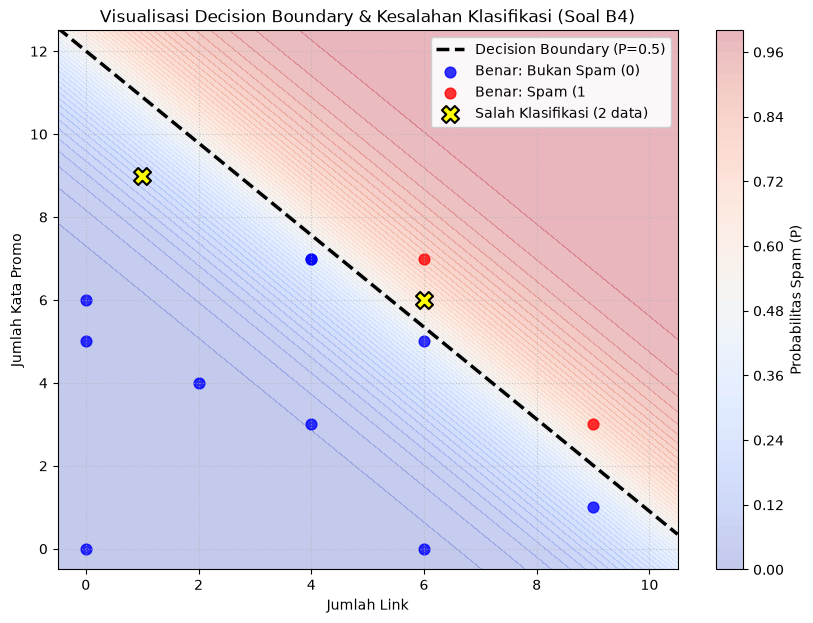

In [14]:
b = log_model.intercept_
m1, m2 = log_model.coefficients_

x1_min, x1_max = X_email[:, 0].min() - 0.5, X_email[:, 0].max() + 0.5
x2_min, x2_max = X_email[:, 1].min() - 0.5, X_email[:, 1].max() + 0.5

xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))

grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs = log_model.predict_proba(grid_points).reshape(xx1.shape)

y_test_pred = log_model.predict(X_test_email)
y_test_email_flat = np.asarray(y_test_email).ravel()
misclassified_mask = y_test_pred != y_test_email_flat

X_test_correct = X_test_email[~misclassified_mask]
X_test_incorrect = X_test_email[misclassified_mask]

plt.figure(figsize=(10, 7))

contour = plt.contourf(xx1, xx2, probs, levels=50, cmap='coolwarm', alpha=0.3)
plt.colorbar(contour, label='Probabilitas Spam (P)')

x1_boundary = np.linspace(x1_min, x1_max, 100)
x2_boundary = -(b + m1 * x1_boundary) / m2
plt.plot(x1_boundary, x2_boundary, color='black', linestyle='--', linewidth=2.5, label='Decision Boundary (P=0.5)')

correct_not_spam = (y_test_email[~misclassified_mask] == 0)
correct_spam = (y_test_email[~misclassified_mask] == 1)

plt.scatter(X_test_correct[correct_not_spam, 0], X_test_correct[correct_not_spam, 1], 
            color='blue', marker='o', s=60, alpha=0.8, label='Benar: Bukan Spam (0)')
plt.scatter(X_test_correct[correct_spam, 0], X_test_correct[correct_spam, 1], 
            color='red', marker='o', s=60, alpha=0.8, label='Benar: Spam (1')

if len(X_test_incorrect) > 0:
    plt.scatter(X_test_incorrect[:, 0], X_test_incorrect[:, 1], 
                color='yellow', marker='X', s=150, edgecolors='black', linewidth=1.5, 
                zorder=5, label=f'Salah Klasifikasi ({len(X_test_incorrect)} data)')

plt.title('Visualisasi Decision Boundary & Kesalahan Klasifikasi (Soal B4)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', framealpha=0.9)
plt.show()

**Jawaban B4 (analisis):**
- Garis putus-putus hitam pada grafik merepresentasikan batas keputusan di mana nilai probabilitas model bernilai tepat $0.5$ ($P(\text{Spam}) = 0.5$). lalu, garis ini berfungsi sebagai pemisah linier. Wilayah di sisi atas/kanan garis dengan warna latar merah menunjukkan area di mana model mengklasifikasikan email sebagai spam, sedangkan wilayah di sisi bawah/kiri dengan warna latar biru menunjukkan area klasifikasi bukan spam.

- Titik-titik yang ditandai dengan ikon silang kuning berbingkai hitam (X) menunjukkan sampel data testing yang gagal diprediksi dengan benar oleh model. Kesalahan ini umumnya terjadi pada titik-titik data yang berada tepat di dekat garis batas keputusan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [40]:
y_prob_email = log_model.predict_proba(X_test_email)

thresholds = [0.3, 0.5, 0.7]
experiment_results = []

for th in thresholds:
  
    y_pred_th = (y_prob_email >= th).astype(int)

    cm, acc, prec, rec, f1, tn, fp, fn, tp = evaluate_classification(y_test_email, y_pred_th)
    
    experiment_results.append({
        'Threshold': th,
        'True Negative (TN)': tn,
        'False Positive (FP)': fp,
        'False Negative (FN)': fn,
        'True Positive (TP)': tp,
        'Precision': prec,
        'Recall': rec
    })
df_threshold_exp = pd.DataFrame(experiment_results)

print("=== Tabel Perbandingan Eksperimen Threshold ===")
display(df_threshold_exp.round(4))

=== Tabel Perbandingan Eksperimen Threshold ===


,Threshold,True Negative (TN),False Positive (FP),False Negative (FN),True Positive (TP),Precision,Recall
0,0.3,7,5,1,2,0.2857,0.6667
1,0.5,11,1,1,2,0.6667,0.6667
2,0.7,12,0,2,1,1.0000,0.3333


**Jawaban B5 (analisis):**
- Menurunkan Threshold ke 0.3 membuat Model menjadi lebih "agresif" dalam mendeteksi spam (lebih mudah melabeli suatu email sebagai spam), sedangkan menaikkan Threshold ke 0.7 membuat Model menjadi lebih "konservatif" dan berhati-hati sebelum melabeli email sebagai spam.

- untuk threshold yang saya pilih adalah  0.7 (atau minimal 0.5 tergantung karakteristik data). alasannya yaitu dengan menggunakan threshold yang lebih tinggi (0.7), kita dapat meminimalisir sekecil mungkin risiko email penting pengguna masuk ke folder spam. Meskipun ada beberapa email spam yang lolos ke inbox, hal tersebut jauh lebih aman dan dapat ditoleransi dibandingkan jika pengguna kehilangan informasi atau pesan penting dari rekan kerja.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [16]:
X_new_emails = np.array([
    [1, 2],   
    [5, 6],   
    [9, 10],  
    [2, 11]   
])

probabilities = log_model.predict_proba(X_new_emails)

chosen_threshold = 0.7
predicted_classes = (probabilities >= chosen_threshold).astype(int)

df_pred_new = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': X_new_emails[:, 0],
    'KataPromo': X_new_emails[:, 1],
    'Probabilitas Spam': probabilities,
    'Prediksi Kelas (0/1)': predicted_classes
})

df_pred_new['Status Email'] = df_pred_new['Prediksi Kelas (0/1)'].apply(
    lambda x: 'Spam (1)' if x == 1 else 'Bukan Spam (0)'
)

print(f"=== Hasil Prediksi Email Baru (Menggunakan Threshold = {chosen_threshold}) ===")
display(df_pred_new[['Email', 'JumlahLink', 'KataPromo', 'Probabilitas Spam', 'Status Email']].round(4))

=== Hasil Prediksi Email Baru (Menggunakan Threshold = 0.7) ===


,Email,JumlahLink,KataPromo,Probabilitas Spam,Status Email
0,E1,1,2,0.0006,Bukan Spam (0)
1,E2,5,6,0.4068,Bukan Spam (0)
2,E3,9,10,0.9986,Spam (1)
3,E4,2,11,0.7316,Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
- Karena Logistic Regression menggunakan prinsip dasar regresi linier untuk menghitung kombinasi linier dari fitur-fitur input.
- Fungsi sigmoid adalah mengubah nilai kontinu tak terbatas menjadi rentang nilai 0 hingga 1

**Jawaban C2:**
- Linear Regression di materi bisa dilatih dengan normal equation atau gradient descent. Normal Equation mencari parameter optimal secara langsung menggunakan rumus matematika, sedangkan Gradient Descent memperbarui bobot model secara iteratif menggunakan tingkat pembelajaran dan turunan fungsi loss.
- kita dapat menggunakan Gradient Descent ketika ukuran dataset sangat besar atau memiliki jumlah fitur yang sangat banyak.

**Jawaban C3:**
- Evaluasi harus dilakukan pada data testing agar kita dapat menguji kemampuan generalisasi model terhadap data baru yang belum pernah dilihat sebelumnya. 
- Overfitting adalah kondisi dalam machine learning atau statistik di mana suatu model terlalu cocok dengan data pelatihan, sehingga gagal memberikan prediksi yang akurat ketika dihadapkan pada data baru atau data uji.

**Jawaban C4:**
- karena MSE dapat digunakan untuk mengukur rata-rata kuadrat jarak nilai prediksi terhadap nilai aktualnya, sedangkan Logistic Regression menggunakan log loss agar fungsi kerugian tetap konveks dan efektif mengevaluasi kesalahan prediksi probabilitas.

**Jawaban C5:**
- adanya perbedaan pada nilai random state yang menggunakan dua digit NIM terakhir setiap orang maka hasilnya akan berbeda

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [30]:
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

sklearn_lin_model = SklearnLinearRegression()
sklearn_lin_model.fit(X_train, y_train)

print("=== Perbandingan Linear Regression ===")
print(f"Manual Intercept  : {model.intercept_:.4f} | Sklearn Intercept  : {sklearn_lin_model.intercept_:.4f}")

print(f"Manual Koefisien  : {model.coefficients_[0]:.4f} | Sklearn Koefisien  : {sklearn_lin_model.coef_[0]:.4f}")


sklearn_log_model = SklearnLogisticRegression(penalty=None, solver='lbfgs')
sklearn_log_model.fit(X_train_email, y_train_email)

print("\n=== Perbandingan Logistic Regression ===")
print(f"Manual Intercept (b)     : {log_model.intercept_:.4f}")
print(f"Sklearn Intercept (b)    : {sklearn_log_model.intercept_[0]:.4f}")
print(f"Manual Koefisien (m1,m2) : JumlahLink = {log_model.coefficients_[0]:.4f}, KataPromo = {log_model.coefficients_[1]:.4f}")
print(f"Sklearn Koefisien (m1,m2): JumlahLink = {sklearn_log_model.coef_[0][0]:.4f}, KataPromo = {sklearn_log_model.coef_[0][1]:.4f}")

=== Perbandingan Linear Regression ===
Manual Intercept  : 28.2692 | Sklearn Intercept  : 28.2692
Manual Koefisien  : 9.0893 | Sklearn Koefisien  : 9.0893

=== Perbandingan Logistic Regression ===
Manual Intercept (b)     : -9.9338
Sklearn Intercept (b)    : -10.4579
Manual Koefisien (m1,m2) : JumlahLink = 0.9186, KataPromo = 0.8272
Sklearn Koefisien (m1,m2): JumlahLink = 0.9699, KataPromo = 0.8668


c:\Users\HP 14S\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**
- Menurut saya, nilai intercept (28.2692) dan koefisien (9.0893) yang dihasilkan oleh model manual menunjukkan hasil yang sama persis dengan model dari sklearn.linear_model.LinearRegression. ini terbukti bahwa Linear Regression berbasis NumPy telah akurat